# 05 — Cross-Layer SAE Feature Correspondence in PIE

## Objective

Assess how sparse autoencoder (SAE) features correspond across adjacent blocks of the pretrained PIE model. The analysis uses **14 independently initialized, layer-specific SAEs** trained in notebook 03, fixed validation activations from notebook 02, and feature–gene catalogs and biological annotations from notebook 04. No SAE is trained here.

We examine four complementary properties: (i) decoder-dictionary direction similarity, (ii) co-activation on aligned validation positions, (iii) decoder feature–gene overlap, and (iv) agreement of functional annotations. We compare features **only across adjacent blocks within the same architectural component**: 3 encoder pairs, 5 processor pairs, and 3 decoder pairs. Encoder/processor positions are latent slots; decoder positions are output genes. The two types of positions are not pooled.

Geometrically matched features are *candidates* for cross-layer correspondence; similarity, co-activation and enrichment do not establish identity or causal transfer.

## 1. Inputs and provenance

Load the fixed independent-initialization SAE series from its manifest. Paths are resolved relative to the project root; missing checkpoints or incomplete inputs cause a visible failure, never a fallback to the archived seed-42 series.

In [1]:
from pathlib import Path
import sys
import csv
import json
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

_cwd = Path.cwd().resolve()
_project_candidates = (_cwd, *_cwd.parents)
PROJECT_ROOT = next(
    (candidate for candidate in _project_candidates
     if (candidate / "results" / "sae_training" / "independent_sae_manifest.json").is_file()),
    None,
)
assert PROJECT_ROOT is not None, "PIE-SAE project root not found"

MANIFEST_PATH = PROJECT_ROOT / "results" / "sae_training" / "independent_sae_manifest.json"
OUTPUT_DIR = PROJECT_ROOT / "results" / "cross_layer_independent"
assert MANIFEST_PATH.is_file(), MANIFEST_PATH

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
assert manifest["training_config"]["n_features"] == 3072
assert manifest["training_config"]["topk"] == 32
assert manifest["training_config"]["normalization"] == "original_dim1"

layer_order = (
    [f"encoder.{i}" for i in range(4)]
    + [f"processor.{i}" for i in range(6)]
    + [f"decoder.{i}" for i in range(4)]
)
registry = {row["layer"]: row for row in manifest["checkpoints"]}
assert len(registry) == 14 and set(registry) == set(layer_order)
assert len({registry[name]["init_seed"] for name in layer_order}) == 14
assert manifest["series"] == "PIE-SAE independent layer-wise", manifest["series"]

for name in layer_order:
    path = PROJECT_ROOT / registry[name]["checkpoint"]
    assert path.is_file(), path
    assert "sae_protocol_tests" in path.parts, path

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_ROOT)
print("Checkpoint series:", manifest["series"])
print("Layers verified:", len(registry))
print("Device:", DEVICE)
print("No SAE training will be performed.")

Project: D:\bio_paper\pie-sae
Checkpoint series: PIE-SAE independent layer-wise
Layers verified: 14
Device: cuda
No SAE training will be performed.


## 2. Nearest-neighbor correspondence of SAE dictionary directions

Each SAE decoder dictionary has columns \(w_j\in\mathbb R^{768}\) representing its 3072 feature directions. For each source-layer feature \(i\), select the destination-layer direction \(j\) maximizing **signed cosine similarity**, \(\cos(w_i,w_j)\). Signed similarity is appropriate here because the corresponding sparse feature activations are nonnegative; flipping the sign of a decoder atom is not necessarily a symmetry.

A **mutual nearest neighbor (MNN)** is a pair of features which select each other. We do **not** assume that identical feature indices indicate correspondence. This geometric screening uses all 11 adjacent within-component pairs.

 1/11 encoder.0    -> encoder.1    | median cosine=0.4102 | mutual pairs=810
 2/11 encoder.1    -> encoder.2    | median cosine=0.4927 | mutual pairs=904
 3/11 encoder.2    -> encoder.3    | median cosine=0.5538 | mutual pairs=928
 4/11 processor.0  -> processor.1  | median cosine=0.6198 | mutual pairs=1059
 5/11 processor.1  -> processor.2  | median cosine=0.6249 | mutual pairs=1100
 6/11 processor.2  -> processor.3  | median cosine=0.6279 | mutual pairs=1132
 7/11 processor.3  -> processor.4  | median cosine=0.6391 | mutual pairs=1180
 8/11 processor.4  -> processor.5  | median cosine=0.6402 | mutual pairs=1227
 9/11 decoder.0    -> decoder.1    | median cosine=0.2407 | mutual pairs=1255
10/11 decoder.1    -> decoder.2    | median cosine=0.2551 | mutual pairs=1374
11/11 decoder.2    -> decoder.3    | median cosine=0.2690 | mutual pairs=1442


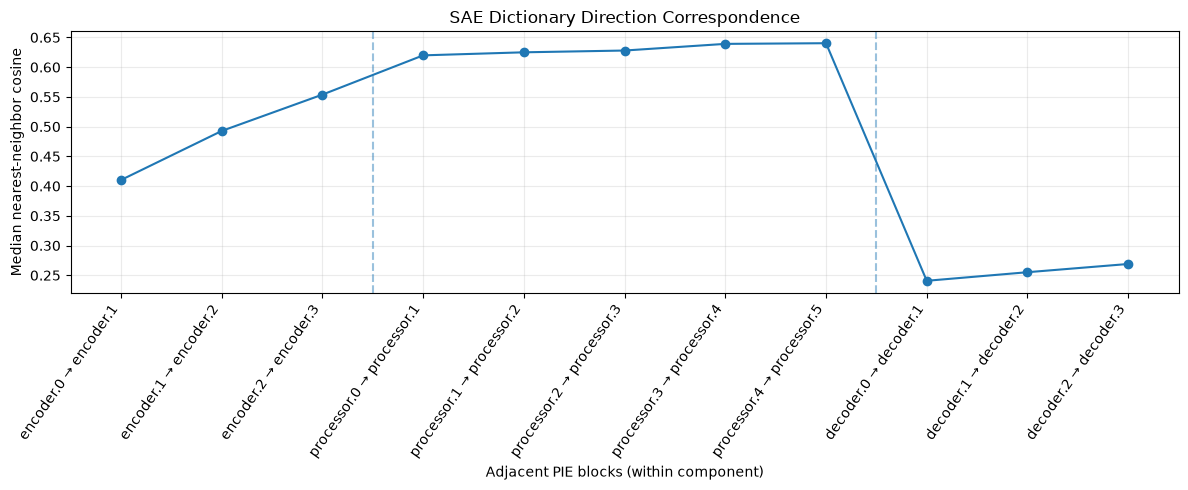


Saved: D:\bio_paper\pie-sae\results\cross_layer_independent\dictionary_correspondence.csv
Saved: D:\bio_paper\pie-sae\results\cross_layer_independent\dictionary_correspondence.json
Saved: D:\bio_paper\pie-sae\results\cross_layer_independent\adjacent_dictionary_cosine.png


In [2]:
def dictionary_vectors(layer: str) -> torch.Tensor:
    """Return normalized SAE decoder directions (3072, 768)."""
    path = PROJECT_ROOT / registry[layer]["checkpoint"]
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    config = checkpoint["config"]
    assert config["layer"] == layer
    assert config["init_seed"] == registry[layer]["init_seed"]
    assert (config["d_model"], config["n_features"], config["topk"]) == (768, 3072, 32)
    W = checkpoint["model_state_dict"]["W_dec.weight"].float()
    assert W.shape == (768, 3072) and torch.isfinite(W).all()
    assert torch.all(torch.linalg.vector_norm(W, dim=0) > 0)
    return F.normalize(W, dim=0).T.contiguous().to(DEVICE)

@torch.inference_mode()
def compare_dictionary_pair(layer_a: str, layer_b: str) -> dict:
    A, B = dictionary_vectors(layer_a), dictionary_vectors(layer_b)
    sim = A @ B.T  # signed directional cosine; both SAEs use nonnegative feature activations
    best_cos, match_ab = sim.max(dim=1)
    match_ba = sim.argmax(dim=0)
    ids = torch.arange(A.shape[0], device=DEVICE)
    mutual = match_ba[match_ab] == ids
    same_index = (match_ab == ids)
    result = {
        "layer_a": layer_a,
        "layer_b": layer_b,
        "mean_best_cosine": float(best_cos.mean().item()),
        "median_best_cosine": float(best_cos.median().item()),
        "p95_best_cosine": float(torch.quantile(best_cos, 0.95).item()),
        "mutual_nn_pairs": int(mutual.sum().item()),
        "same_index_best_matches": int(same_index.sum().item()),
        "n_features": int(A.shape[0]),
    }
    return result, {
        "match_ab": match_ab.cpu().numpy(),
        "best_cosine": best_cos.cpu().numpy(),
        "mutual_mask": mutual.cpu().numpy(),
    }



adjacent_pairs = (
    [(f"encoder.{i}", f"encoder.{i + 1}") for i in range(3)]
    + [(f"processor.{i}", f"processor.{i + 1}") for i in range(5)]
    + [(f"decoder.{i}", f"decoder.{i + 1}") for i in range(3)]
)
assert len(adjacent_pairs) == 11

rows = []
MATCH_DIR = OUTPUT_DIR / "dictionary_matches"
MATCH_DIR.mkdir(parents=True, exist_ok=True)

for i, (a, b) in enumerate(adjacent_pairs, 1):
    # Each pair is explicitly recomputed from the two source checkpoints.
    result, matches = compare_dictionary_pair(a, b)
    rows.append(result)
    output_path = MATCH_DIR / f"{a.replace('.', '_')}_to_{b.replace('.', '_')}.npz"
    np.savez_compressed(output_path, **matches)
    print(f"{i:2d}/11 {a:12s} -> {b:12s} | "
          f"median cosine={result['median_best_cosine']:.4f} | "
          f"mutual pairs={result['mutual_nn_pairs']}")

assert len(rows) == 11
csv_path = OUTPUT_DIR / "dictionary_correspondence.csv"
with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

json_path = OUTPUT_DIR / "dictionary_correspondence.json"
json_path.write_text(json.dumps({
    "series": manifest["series"],
    "manifest_path": str(MANIFEST_PATH.relative_to(PROJECT_ROOT)),
    "comparison": "signed nearest-neighbor cosine similarity of SAE decoder directions",
    "pairs": rows,
}, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(rows))
ax.plot(x, [r["median_best_cosine"] for r in rows], marker="o")
ax.axvline(2.5, linestyle="--", alpha=0.45)
ax.axvline(7.5, linestyle="--", alpha=0.45)
ax.set_xticks(x)
ax.set_xticklabels([f"{r['layer_a']} → {r['layer_b']}" for r in rows], rotation=55, ha="right")
ax.set_ylabel("Median nearest-neighbor cosine")
ax.set_xlabel("Adjacent PIE blocks (within component)")
ax.set_title("SAE Dictionary Direction Correspondence")
ax.grid(alpha=0.25)
fig.tight_layout()
fig_path = OUTPUT_DIR / "adjacent_dictionary_cosine.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("\nSaved:", csv_path)
print("Saved:", json_path)
print("Saved:", fig_path)

## 3. Co-activation on aligned validation observations

For each matched source feature \(A\) and destination feature \(B\), estimate \(P(B>0\mid A>0)\) from SAE activation masks at the **same held-out condition and position**. We report an exploratory one-permutation baseline and a marginal-frequency independence expectation. The later permutation analysis (Section 6) is the actual null-distribution test; a single shuffle does not yield a p-value.

Decoder observations correspond to aligned output genes, while encoder/processor observations correspond to aligned latent slots. Their sampling units have different meanings, so their absolute rates must be compared cautiously.

In [3]:
import h5py

SAE_SRC = PROJECT_ROOT / "external" / "bio-sae" / "src"
assert (SAE_SRC / "sae_model.py").is_file(), SAE_SRC
if str(SAE_SRC) not in sys.path:
    sys.path.insert(0, str(SAE_SRC))
from sae_model import TopKSAE

VAL_PATH = PROJECT_ROOT / "data" / "activations" / "expanded_128_32" / "val_32.h5"
assert VAL_PATH.is_file(), VAL_PATH

def load_cross_layer_sae(layer):

    checkpoint_path = (
        PROJECT_ROOT / registry[layer]["checkpoint"]
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    assert checkpoint["config"]["layer"] == layer
    assert (
        checkpoint["config"]["init_seed"]
        == registry[layer]["init_seed"]
    )

    model = TopKSAE(
        d_model=768,
        n_features=3072,
        k=32,
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True,
    )

    model = model.to(DEVICE).eval()

    mean = torch.from_numpy(
        np.load(checkpoint_path.parent / "activation_mean.npy")
    ).to(device=DEVICE, dtype=torch.float32)

    assert mean.shape == (768,)

    return model, mean


import csv
import json
import h5py
import numpy as np
import torch

COACT_DIR = OUTPUT_DIR / "coactivation"
COACT_DIR.mkdir(parents=True, exist_ok=True)


@torch.inference_mode()
def analyze_coactivation_pair(layer_a, layer_b, seed=42):

    component_a, index_a = layer_a.split(".")
    component_b, index_b = layer_b.split(".")

    assert component_a == component_b

    match_path = (
        MATCH_DIR
        / f"{layer_a.replace('.', '_')}_to_"
          f"{layer_b.replace('.', '_')}.npz"
    )

    assert match_path.is_file(), match_path

    with np.load(match_path) as data:
        match_ab = data["match_ab"].copy()
        mutual_mask = data["mutual_mask"].copy()

    ids_a = np.flatnonzero(mutual_mask)
    ids_b = match_ab[ids_a]

    assert len(ids_a) > 0
    assert len(np.unique(ids_b)) == len(ids_b)

    rng = np.random.default_rng(seed)
    permutation = rng.permutation(len(ids_b))
    shuffled_ids_b = ids_b[permutation]

    sae_a, mean_a = load_cross_layer_sae(layer_a)
    sae_b, mean_b = load_cross_layer_sae(layer_b)

    a_idx = torch.as_tensor(ids_a, device=DEVICE)
    b_idx = torch.as_tensor(ids_b, device=DEVICE)
    shuffled_idx = torch.as_tensor(
        shuffled_ids_b, device=DEVICE
    )

    n_pairs = len(ids_a)

    count_a = np.zeros(n_pairs, dtype=np.int64)
    count_b = np.zeros(n_pairs, dtype=np.int64)

    joint_matched = np.zeros(n_pairs, dtype=np.int64)
    joint_shuffled = np.zeros(n_pairs, dtype=np.int64)

    n_observations = 0

    with h5py.File(VAL_PATH, "r") as h5:

        data_a = h5[component_a][index_a]
        data_b = h5[component_b][index_b]

        assert data_a.shape == data_b.shape
        assert data_a.shape[0] == 32
        assert data_a.shape[2] == 768

        for condition in range(data_a.shape[0]):

            n_positions = data_a.shape[1]

            for start in range(0, n_positions, 256):

                end = min(start + 256, n_positions)

                x_a = torch.from_numpy(
                    np.asarray(data_a[condition, start:end])
                ).to(DEVICE)

                x_b = torch.from_numpy(
                    np.asarray(data_b[condition, start:end])
                ).to(DEVICE)

                z_a, _ = sae_a.encode(x_a - mean_a)
                z_b, _ = sae_b.encode(x_b - mean_b)

                active_a = z_a[:, a_idx] > 0
                active_b = z_b[:, b_idx] > 0
                active_shuffled = (
                    z_b[:, shuffled_idx] > 0
                )

                count_a += active_a.sum(0).cpu().numpy()
                count_b += active_b.sum(0).cpu().numpy()

                joint_matched += (
                    (active_a & active_b)
                    .sum(0).cpu().numpy()
                )

                joint_shuffled += (
                    (active_a & active_shuffled)
                    .sum(0).cpu().numpy()
                )

                n_observations += end - start

    assert n_observations > 0
    assert count_a.sum() > 0

    denominator = float(count_a.sum())

    observed = float(joint_matched.sum() / denominator)
    shuffled = float(joint_shuffled.sum() / denominator)

    expected_matched = float(
        np.sum(
            count_a.astype(float) * count_b.astype(float)
        ) / (n_observations * denominator)
    )

    expected_shuffled = float(
        np.sum(
            count_a.astype(float)
            * count_b[permutation].astype(float)
        ) / (n_observations * denominator)
    )

    result = {
        "layer_a": layer_a,
        "layer_b": layer_b,
        "mutual_pairs": n_pairs,
        "observations": n_observations,
        "matched_conditional": observed,
        "shuffled_conditional": shuffled,
        "expected_matched_independence": expected_matched,
        "expected_shuffled_independence": expected_shuffled,
        "seed": seed,
    }

    assert all(
        0 <= result[key] <= 1
        for key in (
            "matched_conditional",
            "shuffled_conditional",
            "expected_matched_independence",
            "expected_shuffled_independence",
        )
    )

    return result


# Analyze all within-component adjacent pairs.
coactivation_results = []

for i, (layer_a, layer_b) in enumerate(
    adjacent_pairs, start=1
):

    result = analyze_coactivation_pair(
        layer_a,
        layer_b,
        seed=42 + i,
    )

    coactivation_results.append(result)

    print(
        f"{i:2d}/11 | "
        f"{layer_a:12} -> {layer_b:12} | "
        f"matched={result['matched_conditional']:.4f} | "
        f"shuffled={result['shuffled_conditional']:.4f} | "
        f"independent={result['expected_matched_independence']:.4f}"
    )


assert len(coactivation_results) == 11


# Save results.
csv_path = COACT_DIR / "all_pairs_coactivation.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(coactivation_results[0].keys()),
    )
    writer.writeheader()
    writer.writerows(coactivation_results)


json_path = COACT_DIR / "all_pairs_coactivation.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "sae_series": "independent",
            "split": "validation",
            "control": "single shuffled correspondence",
            "results": coactivation_results,
        },
        f,
        indent=2,
    )


print("\n" + "=" * 65)
print("CROSS-LAYER CO-ACTIVATION — ALL 11 PAIRS")
print("=" * 65)

print("Pairs analyzed:", len(coactivation_results))
print("CSV:", csv_path)
print("JSON:", json_path)

print("\nCross-layer co-activation analysis completed.")

 1/11 | encoder.0    -> encoder.1    | matched=0.4313 | shuffled=0.0083 | independent=0.0255
 2/11 | encoder.1    -> encoder.2    | matched=0.4989 | shuffled=0.0150 | independent=0.0443
 3/11 | encoder.2    -> encoder.3    | matched=0.4393 | shuffled=0.0122 | independent=0.0373
 4/11 | processor.0  -> processor.1  | matched=0.5202 | shuffled=0.0101 | independent=0.0537
 5/11 | processor.1  -> processor.2  | matched=0.5140 | shuffled=0.0122 | independent=0.0517
 6/11 | processor.2  -> processor.3  | matched=0.4935 | shuffled=0.0122 | independent=0.0482
 7/11 | processor.3  -> processor.4  | matched=0.4918 | shuffled=0.0128 | independent=0.0448
 8/11 | processor.4  -> processor.5  | matched=0.4902 | shuffled=0.0161 | independent=0.0414
 9/11 | decoder.0    -> decoder.1    | matched=0.3389 | shuffled=0.0103 | independent=0.0840
10/11 | decoder.1    -> decoder.2    | matched=0.3576 | shuffled=0.0112 | independent=0.0837
11/11 | decoder.2    -> decoder.3    | matched=0.4053 | shuffled=0.014

## 4. Decoder feature–gene correspondence

For each decoder MNN pair, compare the Top-20 gene sets produced in notebook 04 using both training and held-out validation conditions. Report mean intersection size, Jaccard similarity, the fraction of pairs with shared genes, and a null obtained by randomly reassigning destination feature identities among the MNN pairs (500 permutations). The same trained SAEs and feature identities are used across train and validation.

Agreement of gene sets reflects gene-associated structure; it does not establish a perturbation-dependent biological mechanism.

In [4]:
import json
import csv
import numpy as np

CATALOG_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "feature_catalogs"
)

BIO_DIR = OUTPUT_DIR / "biological_correspondence"
BIO_DIR.mkdir(parents=True, exist_ok=True)

N_PERMUTATIONS = 500
rng = np.random.default_rng(42)


def load_gene_sets(layer, split):

    layer_index = int(layer.split(".")[1])

    path = (
        CATALOG_DIR
        / f"decoder_{layer_index}_{split}_catalog.json"
    )

    with open(path, encoding="utf-8") as f:
        catalog = json.load(f)

    features = catalog["features"]

    assert len(features) == 3072

    gene_sets = []

    for j, feature in enumerate(features):

        assert feature["feature_idx"] == j

        genes = {
            gene["gene_id"]
            for gene in feature["top_genes"]
        }

        assert len(genes) <= 20
        gene_sets.append(genes)

    return gene_sets


results = []

decoder_pairs = [
    ("decoder.0", "decoder.1"),
    ("decoder.1", "decoder.2"),
    ("decoder.2", "decoder.3"),
]

for layer_a, layer_b in decoder_pairs:

    match_path = (
        MATCH_DIR
        / f"{layer_a.replace('.', '_')}_to_"
          f"{layer_b.replace('.', '_')}.npz"
    )

    with np.load(match_path) as data:
        match_ab = data["match_ab"].copy()
        mutual_mask = data["mutual_mask"].copy()

    ids_a = np.flatnonzero(mutual_mask)
    ids_b = match_ab[ids_a]

    assert len(ids_a) > 0
    assert len(np.unique(ids_b)) == len(ids_b)

    for split in ("train", "validation"):

        genes_a = load_gene_sets(layer_a, split)
        genes_b = load_gene_sets(layer_b, split)

        overlaps = np.array([
            len(genes_a[int(i)] & genes_b[int(j)])
            for i, j in zip(ids_a, ids_b)
        ])

        jaccards = np.array([
            len(genes_a[int(i)] & genes_b[int(j)])
            / max(
                len(genes_a[int(i)] | genes_b[int(j)]),
                1,
            )
            for i, j in zip(ids_a, ids_b)
        ])

        null_means = np.empty(
            N_PERMUTATIONS,
            dtype=np.float64,
        )

        for p in range(N_PERMUTATIONS):

            shuffled_b = rng.permutation(ids_b)

            null_means[p] = np.mean([
                len(genes_a[int(i)] & genes_b[int(j)])
                for i, j in zip(ids_a, shuffled_b)
            ])

        observed = float(overlaps.mean())

        empirical_p = float(
            (1 + np.count_nonzero(null_means >= observed))
            / (N_PERMUTATIONS + 1)
        )

        result = {
            "layer_a": layer_a,
            "layer_b": layer_b,
            "split": split,
            "mutual_pairs": len(ids_a),
            "mean_gene_overlap": observed,
            "median_gene_overlap": float(np.median(overlaps)),
            "mean_jaccard": float(jaccards.mean()),
            "fraction_with_overlap": float(np.mean(overlaps > 0)),
            "null_mean_overlap": float(null_means.mean()),
            "empirical_p": empirical_p,
        }

        results.append(result)

        print(
            f"{layer_a} -> {layer_b} | "
            f"{split:<10} | "
            f"pairs={len(ids_a):4d} | "
            f"overlap={observed:.3f} | "
            f"null={null_means.mean():.3f} | "
            f"p={empirical_p:.4f}"
        )


assert len(results) == 6

csv_path = BIO_DIR / "decoder_gene_correspondence.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(results[0].keys()),
    )

    writer.writeheader()
    writer.writerows(results)


json_path = BIO_DIR / "decoder_gene_correspondence.json"

with open(json_path, "w", encoding="utf-8") as f:

    json.dump(
        {
            "sae_series": "independent",
            "n_permutations": N_PERMUTATIONS,
            "seed": 42,
            "results": results,
        },
        f,
        indent=2,
    )


print("\n" + "=" * 65)
print("BIOLOGICAL CROSS-LAYER CORRESPONDENCE COMPLETED")
print("=" * 65)

print("Layer/split comparisons:", len(results))
print("CSV:", csv_path)
print("JSON:", json_path)

decoder.0 -> decoder.1 | train      | pairs=1255 | overlap=4.446 | null=0.062 | p=0.0020
decoder.0 -> decoder.1 | validation | pairs=1255 | overlap=4.437 | null=0.063 | p=0.0020
decoder.1 -> decoder.2 | train      | pairs=1374 | overlap=4.622 | null=0.064 | p=0.0020
decoder.1 -> decoder.2 | validation | pairs=1374 | overlap=4.577 | null=0.064 | p=0.0020
decoder.2 -> decoder.3 | train      | pairs=1442 | overlap=5.024 | null=0.064 | p=0.0020
decoder.2 -> decoder.3 | validation | pairs=1442 | overlap=4.894 | null=0.063 | p=0.0020

BIOLOGICAL CROSS-LAYER CORRESPONDENCE COMPLETED
Layer/split comparisons: 6
CSV: D:\bio_paper\pie-sae\results\cross_layer_independent\biological_correspondence\decoder_gene_correspondence.csv
JSON: D:\bio_paper\pie-sae\results\cross_layer_independent\biological_correspondence\decoder_gene_correspondence.json


## 5. Decoder functional-annotation correspondence

Among geometrically matched decoder features, compare significant GO Biological Process, KEGG and Reactome terms obtained from the **training** gene catalogs in notebook 04. Measure the fraction sharing at least one term, and the conditional fraction among pairs where both features are annotated. Use 500 random reassignments of destination feature identities as a baseline. Annotation databases have overlapping and hierarchical terms; shared-term counts are not counts of independent biological mechanisms.

In [5]:
import json
import csv
import numpy as np

ANNOTATION_DIR = (
    PROJECT_ROOT
    / "results"
    / "sae_feature_analysis_independent"
    / "biological_annotations"
)

FUNCTIONAL_DIR = (
    OUTPUT_DIR / "functional_correspondence"
)

FUNCTIONAL_DIR.mkdir(parents=True, exist_ok=True)

SOURCES = {"GO_BP", "KEGG", "Reactome"}
N_PERMUTATIONS = 500

rng = np.random.default_rng(42)


def load_feature_annotations(layer):

    index = int(layer.split(".")[1])

    path = (
        ANNOTATION_DIR
        / f"decoder_{index}_annotations.json"
    )

    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    assert data["summary"]["n_features"] == 3072

    annotations = data["feature_annotations"]

    return [
        {
            (item["source"], item["term"])
            for item in annotations.get(str(j), [])
            if item["source"] in SOURCES
            and item["q_value"] < 0.05
        }
        for j in range(3072)
    ]


decoder_pairs = [
    ("decoder.0", "decoder.1"),
    ("decoder.1", "decoder.2"),
    ("decoder.2", "decoder.3"),
]

functional_results = []

for layer_a, layer_b in decoder_pairs:

    match_path = (
        MATCH_DIR
        / f"{layer_a.replace('.', '_')}_to_"
          f"{layer_b.replace('.', '_')}.npz"
    )

    with np.load(match_path) as data:
        match_ab = data["match_ab"].copy()
        mutual_mask = data["mutual_mask"].copy()

    ids_a = np.flatnonzero(mutual_mask)
    ids_b = match_ab[ids_a]

    annotations_a = load_feature_annotations(layer_a)
    annotations_b = load_feature_annotations(layer_b)

    shared = np.array([
        len(annotations_a[int(i)] & annotations_b[int(j)])
        for i, j in zip(ids_a, ids_b)
    ])

    both_annotated = np.array([
        bool(annotations_a[int(i)])
        and bool(annotations_b[int(j)])
        for i, j in zip(ids_a, ids_b)
    ])

    observed = float(shared.mean())

    null_means = np.empty(
        N_PERMUTATIONS,
        dtype=np.float64,
    )

    for p in range(N_PERMUTATIONS):

        shuffled_b = rng.permutation(ids_b)

        null_means[p] = np.mean([
            len(annotations_a[int(i)] & annotations_b[int(j)])
            for i, j in zip(ids_a, shuffled_b)
        ])

    empirical_p = float(
        (
            1 + np.count_nonzero(null_means >= observed)
        )
        / (N_PERMUTATIONS + 1)
    )

    result = {
        "layer_a": layer_a,
        "layer_b": layer_b,
        "mutual_pairs": len(ids_a),
        "mean_shared_terms": observed,
        "fraction_with_shared_terms": float(
            np.mean(shared > 0)
        ),
        "fraction_both_annotated": float(
            np.mean(both_annotated)
        ),
        "fraction_shared_given_both": float(
            np.mean(shared[both_annotated] > 0)
        ) if both_annotated.any() else 0.0,
        "null_mean_shared_terms": float(
            null_means.mean()
        ),
        "empirical_p": empirical_p,
    }

    functional_results.append(result)

    print("\n" + "=" * 65)
    print(f"{layer_a} -> {layer_b}")
    print("=" * 65)

    print("Mutual pairs:", len(ids_a))
    print("Mean shared terms:", f"{observed:.3f}")

    print(
        "Pairs sharing at least one term:",
        f"{100 * result['fraction_with_shared_terms']:.2f}%"
    )

    print(
        "Both features annotated:",
        f"{100 * result['fraction_both_annotated']:.2f}%"
    )

    print(
        "Shared term among jointly annotated pairs:",
        f"{100 * result['fraction_shared_given_both']:.2f}%"
    )

    print(
        "Permutation null:",
        f"{result['null_mean_shared_terms']:.3f}"
    )

    print("Empirical p-value:", f"{empirical_p:.4f}")


assert len(functional_results) == 3


# Save results.

csv_path = (
    FUNCTIONAL_DIR
    / "decoder_functional_correspondence.csv"
)

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(functional_results[0].keys()),
    )

    writer.writeheader()
    writer.writerows(functional_results)


json_path = (
    FUNCTIONAL_DIR
    / "decoder_functional_correspondence.json"
)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "sources": sorted(SOURCES),
            "n_permutations": N_PERMUTATIONS,
            "seed": 42,
            "results": functional_results,
        },
        f,
        indent=2,
    )


print("\nFunctional correspondence analysis completed.")
print("CSV:", csv_path)
print("JSON:", json_path)


decoder.0 -> decoder.1
Mutual pairs: 1255
Mean shared terms: 3.873
Pairs sharing at least one term: 29.00%
Both features annotated: 42.71%
Shared term among jointly annotated pairs: 67.91%
Permutation null: 0.041
Empirical p-value: 0.0020

decoder.1 -> decoder.2
Mutual pairs: 1374
Mean shared terms: 4.103
Pairs sharing at least one term: 31.95%
Both features annotated: 43.01%
Shared term among jointly annotated pairs: 74.28%
Permutation null: 0.038
Empirical p-value: 0.0020

decoder.2 -> decoder.3
Mutual pairs: 1442
Mean shared terms: 4.435
Pairs sharing at least one term: 31.97%
Both features annotated: 42.37%
Shared term among jointly annotated pairs: 75.45%
Permutation null: 0.043
Empirical p-value: 0.0020

Functional correspondence analysis completed.
CSV: D:\bio_paper\pie-sae\results\cross_layer_independent\functional_correspondence\decoder_functional_correspondence.csv
JSON: D:\bio_paper\pie-sae\results\cross_layer_independent\functional_correspondence\decoder_functional_corresp

## 6. Co-activation permutation control

For each of the 11 adjacent pairs, randomly sample 128 aligned positions from each of the 32 validation conditions (4096 observations), retaining the exact same conditions and positions on the two sides. Compute SAE firing masks once and compare the observed MNN co-activation with 200 independent permutations of the destination-feature matching. The resulting empirical p-values are **unadjusted** and limited by a resolution of \(1/(200+1)\approx0.00498\); they are not direct tests of causal biological conservation.

Sampling tokens within the same condition is not equivalent to sampling independent perturbation experiments. These controls assess feature-matching specificity conditional on the observed activations and the available matched pairs.

In [6]:
import json
import h5py
import numpy as np
import torch

PERM_DIR = OUTPUT_DIR / "coactivation"
PERM_DIR.mkdir(parents=True, exist_ok=True)

N_PERMUTATIONS = 200
POSITIONS_PER_CONDITION = 128


@torch.inference_mode()
def coactivation_permutation_test(layer_a, layer_b, seed=42):

    component_a, index_a = layer_a.split(".")
    component_b, index_b = layer_b.split(".")

    assert component_a == component_b

    match_path = (
        MATCH_DIR
        / f"{layer_a.replace('.', '_')}_to_"
          f"{layer_b.replace('.', '_')}.npz"
    )

    with np.load(match_path) as data:
        match_ab = data["match_ab"].copy()
        mutual_mask = data["mutual_mask"].copy()

    ids_a = np.flatnonzero(mutual_mask)
    ids_b = match_ab[ids_a]

    assert len(ids_a) > 0
    assert len(np.unique(ids_b)) == len(ids_b)

    sae_a, mean_a = load_cross_layer_sae(layer_a)
    sae_b, mean_b = load_cross_layer_sae(layer_b)

    a_idx = torch.as_tensor(ids_a, device=DEVICE)
    b_idx = torch.as_tensor(ids_b, device=DEVICE)

    rng = np.random.default_rng(seed)

    masks_a = []
    masks_b = []

    with h5py.File(VAL_PATH, "r") as h5:

        data_a = h5[component_a][index_a]
        data_b = h5[component_b][index_b]

        assert data_a.shape == data_b.shape
        assert data_a.shape[0] == 32
        assert data_a.shape[2] == 768

        n_positions = data_a.shape[1]
        n_sample = min(POSITIONS_PER_CONDITION, n_positions)

        for condition in range(32):

            positions = np.sort(
                rng.choice(
                    n_positions,
                    size=n_sample,
                    replace=False,
                )
            )

            x_a = torch.from_numpy(
                np.asarray(data_a[condition, positions, :])
            ).to(DEVICE)

            x_b = torch.from_numpy(
                np.asarray(data_b[condition, positions, :])
            ).to(DEVICE)

            z_a, _ = sae_a.encode(x_a - mean_a)
            z_b, _ = sae_b.encode(x_b - mean_b)

            masks_a.append(
                (z_a[:, a_idx] > 0).cpu().numpy()
            )

            masks_b.append(
                (z_b[:, b_idx] > 0).cpu().numpy()
            )

    A = np.concatenate(masks_a, axis=0)
    B = np.concatenate(masks_b, axis=0)

    assert A.shape == B.shape
    assert A.shape[0] == 32 * n_sample

    denominator = int(A.sum())
    assert denominator > 0

    observed = float(
        np.count_nonzero(A & B) / denominator
    )

    null_values = np.empty(
        N_PERMUTATIONS,
        dtype=np.float64,
    )

    n_pairs = A.shape[1]

    for p in range(N_PERMUTATIONS):

        shuffled = rng.permutation(n_pairs)

        null_values[p] = (
            np.count_nonzero(A & B[:, shuffled])
            / denominator
        )

    empirical_p = float(
        (
            1 + np.count_nonzero(null_values >= observed)
        )
        / (N_PERMUTATIONS + 1)
    )

    result = {
        "layer_a": layer_a,
        "layer_b": layer_b,
        "mutual_pairs": n_pairs,
        "sampled_observations": A.shape[0],
        "observed": observed,
        "null_mean": float(null_values.mean()),
        "null_std": float(null_values.std()),
        "null_p95": float(np.percentile(null_values, 95)),
        "empirical_p": empirical_p,
    }

    del sae_a, sae_b, A, B

    return result


# --------------------------------------------------
# Run controls for all adjacent pairs
# --------------------------------------------------

permutation_results = []

for i, (layer_a, layer_b) in enumerate(
    adjacent_pairs,
    start=1,
):

    result = coactivation_permutation_test(
        layer_a,
        layer_b,
        seed=42,
    )

    permutation_results.append(result)

    print(
        f"{i:2d}/11 | "
        f"{layer_a:12} -> {layer_b:12} | "
        f"observed={result['observed']:.4f} | "
        f"null={result['null_mean']:.4f} | "
        f"p={result['empirical_p']:.4f}"
    )


assert len(permutation_results) == 11

output_path = (
    PERM_DIR / "coactivation_permutation_200.json"
)

with open(output_path, "w", encoding="utf-8") as f:

    json.dump(
        {
            "n_permutations": N_PERMUTATIONS,
            "positions_per_condition": POSITIONS_PER_CONDITION,
            "split": "validation",
            "seed": 42,
            "results": permutation_results,
        },
        f,
        indent=2,
    )

print("\n" + "=" * 65)
print("CO-ACTIVATION PERMUTATION CONTROLS COMPLETED")
print("=" * 65)

print("Pairs tested:", len(permutation_results))
print("Permutations per pair:", N_PERMUTATIONS)
print("Saved:", output_path)

 1/11 | encoder.0    -> encoder.1    | observed=0.4304 | null=0.0094 | p=0.0050
 2/11 | encoder.1    -> encoder.2    | observed=0.4961 | null=0.0132 | p=0.0050
 3/11 | encoder.2    -> encoder.3    | observed=0.4384 | null=0.0126 | p=0.0050
 4/11 | processor.0  -> processor.1  | observed=0.5182 | null=0.0147 | p=0.0050
 5/11 | processor.1  -> processor.2  | observed=0.5146 | null=0.0142 | p=0.0050
 6/11 | processor.2  -> processor.3  | observed=0.4947 | null=0.0139 | p=0.0050
 7/11 | processor.3  -> processor.4  | observed=0.4928 | null=0.0136 | p=0.0050
 8/11 | processor.4  -> processor.5  | observed=0.4891 | null=0.0133 | p=0.0050
 9/11 | decoder.0    -> decoder.1    | observed=0.3393 | null=0.0114 | p=0.0050
10/11 | decoder.1    -> decoder.2    | observed=0.3568 | null=0.0117 | p=0.0050
11/11 | decoder.2    -> decoder.3    | observed=0.4066 | null=0.0119 | p=0.0050

CO-ACTIVATION PERMUTATION CONTROLS COMPLETED
Pairs tested: 11
Permutations per pair: 200
Saved: D:\bio_paper\pie-sae\re

## 7. Summary and visualization

Plot the observed conditional co-activation and the feature-correspondence permutation baseline across all 11 within-component transitions. The two traces are descriptive. The decoder gene-list and functional-annotation metrics are also consolidated into an independently readable table.

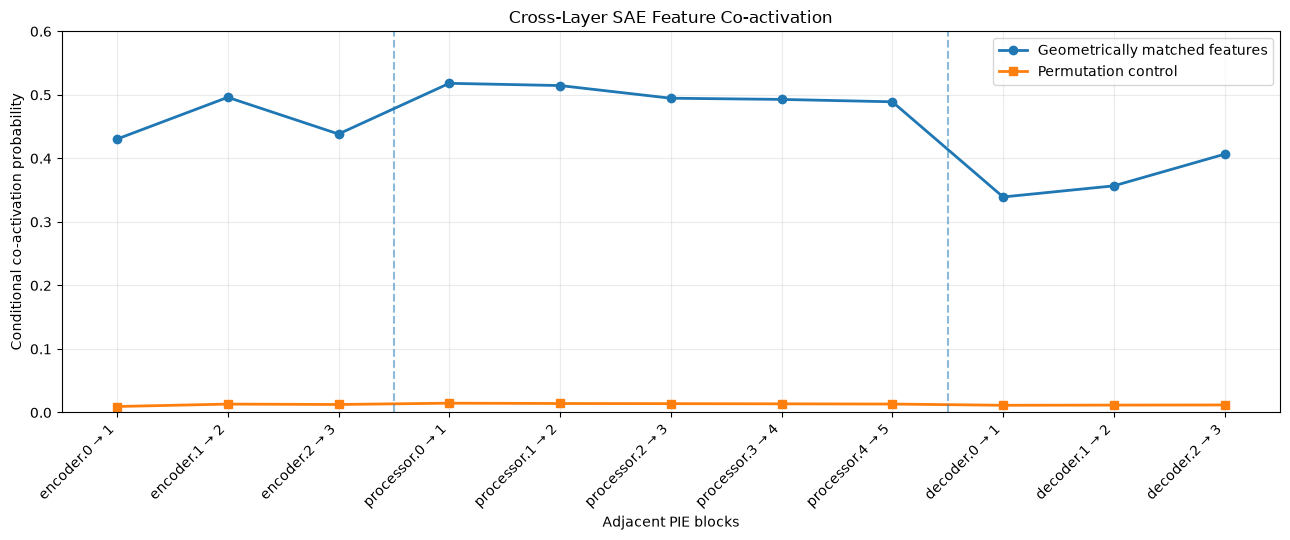

CROSS-LAYER CO-ACTIVATION SUMMARY
encoder.0    -> encoder.1    | Observed=0.4304 | Null=0.0094 | p=0.0050
encoder.1    -> encoder.2    | Observed=0.4961 | Null=0.0132 | p=0.0050
encoder.2    -> encoder.3    | Observed=0.4384 | Null=0.0126 | p=0.0050
processor.0  -> processor.1  | Observed=0.5182 | Null=0.0147 | p=0.0050
processor.1  -> processor.2  | Observed=0.5146 | Null=0.0142 | p=0.0050
processor.2  -> processor.3  | Observed=0.4947 | Null=0.0139 | p=0.0050
processor.3  -> processor.4  | Observed=0.4928 | Null=0.0136 | p=0.0050
processor.4  -> processor.5  | Observed=0.4891 | Null=0.0133 | p=0.0050
decoder.0    -> decoder.1    | Observed=0.3393 | Null=0.0114 | p=0.0050
decoder.1    -> decoder.2    | Observed=0.3568 | Null=0.0117 | p=0.0050
decoder.2    -> decoder.3    | Observed=0.4066 | Null=0.0119 | p=0.0050

Pairs analyzed: 11
Permutations per pair: 200
Figure saved: D:\bio_paper\pie-sae\results\cross_layer_independent\figures\cross_layer_coactivation_summary.png


In [7]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_layer_independent"
)

CONTROL_PATH = (
    RESULTS_DIR
    / "coactivation"
    / "coactivation_permutation_200.json"
)

assert CONTROL_PATH.is_file()

with open(CONTROL_PATH, encoding="utf-8") as f:
    control_data = json.load(f)

rows = control_data["results"]

assert len(rows) == 11

labels = [
    f"{row['layer_a']} → {row['layer_b'].split('.')[-1]}"
    for row in rows
]

observed = np.array([
    row["observed"]
    for row in rows
])

null_mean = np.array([
    row["null_mean"]
    for row in rows
])

p_values = np.array([
    row["empirical_p"]
    for row in rows
])

assert np.isfinite(observed).all()
assert np.isfinite(null_mean).all()

x = np.arange(len(rows))

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    x,
    observed,
    marker="o",
    linewidth=2,
    label="Geometrically matched features",
)

ax.plot(
    x,
    null_mean,
    marker="s",
    linewidth=2,
    label="Permutation control",
)

# Architectural component boundaries
ax.axvline(2.5, linestyle="--", alpha=0.5)
ax.axvline(7.5, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")

ax.set_xlabel("Adjacent PIE blocks")
ax.set_ylabel("Conditional co-activation probability")

ax.set_title(
    "Cross-Layer SAE Feature Co-activation"
)

ax.set_ylim(0, 0.6)

ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_path = (
    FIGURE_DIR
    / "cross_layer_coactivation_summary.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("=" * 65)
print("CROSS-LAYER CO-ACTIVATION SUMMARY")
print("=" * 65)

for row in rows:
    print(
        f"{row['layer_a']:12} -> "
        f"{row['layer_b']:12} | "
        f"Observed={row['observed']:.4f} | "
        f"Null={row['null_mean']:.4f} | "
        f"p={row['empirical_p']:.4f}"
    )

print("\nPairs analyzed:", len(rows))
print("Permutations per pair:", control_data["n_permutations"])
print("Figure saved:", figure_path)

In [8]:
# Consolidate stored outputs from the preceding analyses, without rerunning any SAE.
from pathlib import Path
import csv
import json

summary_root = OUTPUT_DIR
with (summary_root / "dictionary_correspondence.json").open(encoding="utf-8") as f:
    geometry = json.load(f)["pairs"]
with (summary_root / "coactivation" / "all_pairs_coactivation.json").open(encoding="utf-8") as f:
    activation = json.load(f)["results"]
with (summary_root / "coactivation" / "coactivation_permutation_200.json").open(encoding="utf-8") as f:
    controls = json.load(f)["results"]
with (summary_root / "biological_correspondence" / "decoder_gene_correspondence.json").open(encoding="utf-8") as f:
    genes = json.load(f)["results"]
with (summary_root / "functional_correspondence" / "decoder_functional_correspondence.json").open(encoding="utf-8") as f:
    functional = json.load(f)["results"]

pair_key = lambda r: (r["layer_a"], r["layer_b"])
geometry_map = {pair_key(r): r for r in geometry}
activation_map = {pair_key(r): r for r in activation}
controls_map = {pair_key(r): r for r in controls}
genes_map = {pair_key(r): r for r in genes if r["split"] == "validation"}
functional_map = {pair_key(r): r for r in functional}
assert len(geometry_map) == len(activation_map) == len(controls_map) == 11
assert len(genes_map) == len(functional_map) == 3

combined_rows = []
for a, b in adjacent_pairs:
    k = (a, b)
    row = {
        "layer_a": a,
        "layer_b": b,
        "mutual_pairs": geometry_map[k]["mutual_nn_pairs"],
        "median_best_cosine": geometry_map[k]["median_best_cosine"],
        "full_validation_coactivation": activation_map[k]["matched_conditional"],
        "sampled_coactivation": controls_map[k]["observed"],
        "sampled_null_mean": controls_map[k]["null_mean"],
        "coactivation_empirical_p_unadjusted": controls_map[k]["empirical_p"],
        "validation_top20_gene_overlap": genes_map[k]["mean_gene_overlap"] if k in genes_map else "",
        "mean_shared_functional_terms": functional_map[k]["mean_shared_terms"] if k in functional_map else "",
    }
    combined_rows.append(row)

summary_file = summary_root / "cross_layer_summary.csv"
with summary_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(combined_rows[0]))
    writer.writeheader()
    writer.writerows(combined_rows)

print(f"Consolidated {len(combined_rows)} adjacent-layer transitions")
print("Output:", summary_file)
print("\nDecoder-specific gene/annotation correspondence:")
for row in combined_rows[-3:]:
    print(f"{row['layer_a']} -> {row['layer_b']}: "
          f"top-20 overlap={row['validation_top20_gene_overlap']:.3f}, "
          f"shared functional terms={row['mean_shared_functional_terms']:.3f}")

Consolidated 11 adjacent-layer transitions
Output: D:\bio_paper\pie-sae\results\cross_layer_independent\cross_layer_summary.csv

Decoder-specific gene/annotation correspondence:
decoder.0 -> decoder.1: top-20 overlap=4.437, shared functional terms=3.873
decoder.1 -> decoder.2: top-20 overlap=4.577, shared functional terms=4.103
decoder.2 -> decoder.3: top-20 overlap=4.894, shared functional terms=4.435


## 8. Results, interpretation and limitations

**Geometric correspondence.** The median nearest-neighbor signed cosine similarity increases from **0.410** to **0.554** across encoder transitions, remains approximately **0.620–0.640** across processor transitions, and is lower (**0.241–0.269**) across decoder transitions. Mutual-nearest-neighbor pair counts range from **810** (`encoder.0 → encoder.1`) to **1442** (`decoder.2 → decoder.3`). A larger number of mutual matches does not itself imply stronger cosine similarity.

**Co-activation on matched observations.** Across 11 transitions, held-out co-activation of matched features ranges approximately **0.34–0.52**, compared with roughly **0.009–0.015** after random reassignment. The sampled 200-permutation controls yield empirical unadjusted **p = 0.00498** for every pair. This is the **permutation-resolution floor**; it cannot measure smaller p-values. Since these are 11 simultaneous tests, the minimal Bonferroni-adjusted p-value achievable with 200 permutations is approximately **0.0547**. The evidence for elevated co-activation relative to this null is strong descriptively, but strict family-wise significance at 0.05 is not resolved with the present permutation budget.

**Decoder gene associations.** Matched feature pairs share on average **4.44–5.02 genes** among their two Top-20 lists on training conditions and **4.44–4.89** on validation conditions, versus random-matching means around **0.06**. The train–validation similarity demonstrates reproducibility for *fixed* SAEs under different perturbation conditions, not stability across independent refits of the same layer.

**Functional annotations.** Matched decoder features share on average **3.87–4.10 significant GO/KEGG/Reactome terms** in the first two decoder transitions; the complete third-transition value is available in the consolidated results. Among matched pairs for which both features have annotations, the proportion sharing at least one term is **67.9%** (`decoder.0 → decoder.1`) and **74.3%** (`decoder.1 → decoder.2`). Functional annotations are based on overlapping ontologies and gene lists, so they are correlated with the gene-set correspondence result rather than an independent causal validation.

**Interpretation limits.** The analysis addresses *within-component adjacent transitions* only. Comparing SAE decoder columns across hidden states has a nearest-neighbor selection effect (3072 candidates per feature). Co-activation may reflect preserved gene identity and slot structure. Perturbation conditions and gene positions are not statistically independent replicates. No causal patching, perturbation sensitivity of individual features, repeated same-layer SAE refits, or cross-component feature transport is established here. The results support cross-layer *correspondence*, not claims that biological mechanisms are copied, created, destroyed or causally transmitted between layers.

**Relationship to Kendiukhov's work.** The study uses the pretrained PIE architecture and the original TopKSAE implementation to adapt SAE-based dictionary, activation and biological analyses to PIE. Cross-layer nearest-neighbor matching, gene-list permutation tests and the corresponding controls are PIE-specific extensions; they should not be presented as literal reproductions of all of Kendiukhov's experiments.

**Reproducibility.** The notebook expects local HDF5 activation arrays and SAE checkpoints, which are intentionally not tracked in Git. Its outputs are saved under `results/cross_layer_independent/`. Before publication, record package versions, dataset/checkpoint sources and run the notebook once with **Restart Kernel → Run All** in the project virtual environment.